In [282]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [283]:
raw_data = pd.read_csv("loan_data_preprocessed.csv", low_memory=False)

# <u>STEP 1 : OVERVIEW<u>
- An Initial Assessement : Check data structure, number of rows and attributes and any key insight, if possible.

In [285]:
raw_data.shape

(466285, 209)

In [286]:
raw_data.head()

,Unnamed: 0.1,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,...,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY,initial_list_status:f,initial_list_status:w,good_bad
0,0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,...,0,0,0,0,0,0,0,1,0,1
1,1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,...,0,0,0,0,0,0,0,1,0,0
2,2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,...,0,0,0,0,0,0,0,1,0,1
3,3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,...,0,0,0,0,0,0,0,1,0,1
4,4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,...,0,0,0,0,0,0,0,1,0,1


In [287]:
raw_data.good_bad.value_counts()

good_bad
1    415317
0     50968
Name: count, dtype: int64

In [288]:
df=raw_data.good_bad.value_counts(normalize=True)

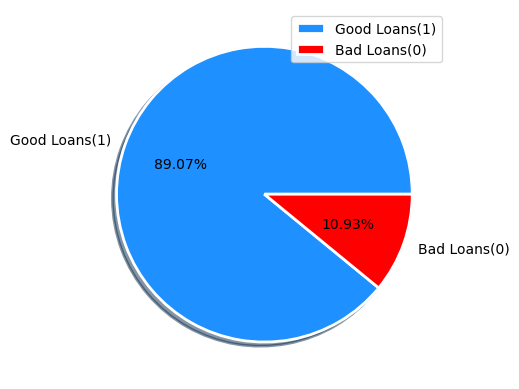

In [289]:
plt.pie(df, autopct='%.2f%%',
       shadow=True,
       labels = ['Good Loans(1)','Bad Loans(0)'],
       colors=['dodgerblue','red'],
       wedgeprops={'edgecolor':'white', 'linewidth': 2})
plt.legend()

## <u>OBSERVATION 1<u>:
- Number of Rows    : 466285
- Number of Columns : 209
- The percentage of Good loans vs Bad Loans are 89.07% and **10.93%** respectively.
- The Data is skewed towards the Good Loans.
- **DEFAULT RATE** : **10.93%**

# <u>STEP 2: DATA CLEANING<u> 
- Taking care of missing values and dropping attributes irrelevant to the our objective.
- Assuming a threshold of 40%.
- If a column has more than 40% data missing, it will be dropped.

In [292]:
missing_data = raw_data.isnull().sum().sort_values(ascending=False)
#missing_data.head(35)

In [293]:
miss_pct = (missing_data/len(raw_data)).sort_values(ascending=False)
col_drop = miss_pct[miss_pct > 0.4].index
raw_data = raw_data.drop(columns = col_drop)

In [294]:
raw_data.shape

(466285, 187)

- Now we drop the columns that are irrelevent to our objective 
- Ex : 'id' , 'member_id' 

In [296]:
#raw_data.columns.tolist()

In [297]:
irr_col = ['Unnamed: 0.1', 'Unnamed: 0', 'id' , 'member_id' , 'url' , 'pymnt_plan', 'desc', 'zip_code'] 
raw_data = raw_data.drop(columns= irr_col, errors='ignore')

In [298]:
raw_data.shape

(466285, 180)

### <u>IMPUTATION :<u> 
- Now we plug in missing values with meaningful alternatives, for both Numeric and Categorical dtypes.

In [300]:
num_col = raw_data.select_dtypes(include = 'number')

In [301]:
cat_col = raw_data.select_dtypes( include = 'object')

- Checking for missing entries for Categorical Variables

In [303]:
num_col.isnull().sum().sort_values(ascending=False)

tot_coll_amt                  70276
tot_cur_bal                   70276
revol_util                      340
collections_12_mths_ex_med      145
loan_amnt                         0
                              ...  
sub_grade:D2                      0
sub_grade:D3                      0
sub_grade:D4                      0
sub_grade:D5                      0
good_bad                          0
Length: 161, dtype: int64

#### We take care of the numerical columns in either of the 2 ways.
- 1. We check for % of missing values for a column. If it is insignificant(1% to 2% or less), we drop the rows.
- 2. If we need to impute, we use median to fill the missing space since the data is skewed.                                                                                          

In [305]:
pct_num_col = (num_col.isnull().sum().sort_values(ascending=False))/len(raw_data)

In [306]:
pct_num_col.head()

tot_coll_amt                  0.150715
tot_cur_bal                   0.150715
revol_util                    0.000729
collections_12_mths_ex_med    0.000311
loan_amnt                     0.000000
dtype: float64

<u>**OBSERVATION**<u>
- We drop the rows from **'revol_util'** and **'collections_12_mths_ex_med'**.
- We also drop  **'tot_coll_amt'** and **'tot_cur_bal'** , despite having **15% missing values**.
- They are not Informative for our Loan Default Analysis. 

In [308]:
raw_data.dropna(subset =['revol_util','collections_12_mths_ex_med'], inplace=True)

In [309]:
raw_data.shape

(465832, 180)

In [310]:
raw_data.drop( columns = ['tot_coll_amt' , 'tot_cur_bal' ] ,inplace=True)

In [311]:
raw_data.shape

(465832, 178)

- Now we check for the Categorical Columns.
- We decide based on relevance to our analysis, what feature to retain, impute or drop

In [313]:
pct_cat_col = (cat_col.isnull().sum().sort_values( ascending = False ))/len(raw_data)

In [314]:
pct_cat_col.head()

emp_title                0.059223
emp_length               0.045098
last_pymnt_d             0.000807
last_credit_pull_d       0.000090
earliest_cr_line_date    0.000062
dtype: float64

- **'emp_length'** and **'emp_title'** is currently left as is; will consider numeric conversion and imputation if deeper employment-based analysis is required.
- **'last_pymnt_d'** , **'last_credit_pull_d'** , **'earliest_cr_line_date'** will be dropped as they are not informative to our objective

In [316]:
data1 = raw_data.drop(columns =['last_pymnt_d' , 'last_credit_pull_d' , 'earliest_cr_line_date'])

In [317]:
data1.shape

(465832, 175)

In [318]:
data_clean = data1.copy(deep=True)

In [319]:
data_clean.head()

,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,...,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY,initial_list_status:f,initial_list_status:w,good_bad
0,5000,5000,4975.0,36 months,10.65,162.87,B,B2,NaN,10+ years,...,0,0,0,0,0,0,0,1,0,1
1,2500,2500,2500.0,60 months,15.27,59.83,C,C4,Ryder,< 1 year,...,0,0,0,0,0,0,0,1,0,0
2,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,...,0,0,0,0,0,0,0,1,0,1
3,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,...,0,0,0,0,0,0,0,1,0,1
4,3000,3000,3000.0,60 months,12.69,67.79,B,B5,University Medical Group,1 year,...,0,0,0,0,0,0,0,1,0,1


# <u>DATA EXPLORATION AND VISUALIZATION<u>
- We know plot graphs from numeric attributes and draw insights.

In [321]:
numeric_att =  data_clean.select_dtypes( include = 'number')

In [322]:
category_att = data_clean.select_dtypes( include = 'object')

In [323]:
#category_att
numeric_att.head(5)

,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,open_acc,...,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY,initial_list_status:f,initial_list_status:w,good_bad
0,5000,5000,4975.0,10.65,162.87,24000.0,27.65,0.0,1.0,3.0,...,0,0,0,0,0,0,0,1,0,1
1,2500,2500,2500.0,15.27,59.83,30000.0,1.00,0.0,5.0,3.0,...,0,0,0,0,0,0,0,1,0,0
2,2400,2400,2400.0,15.96,84.33,12252.0,8.72,0.0,2.0,2.0,...,0,0,0,0,0,0,0,1,0,1
3,10000,10000,10000.0,13.49,339.31,49200.0,20.00,0.0,1.0,10.0,...,0,0,0,0,0,0,0,1,0,1
4,3000,3000,3000.0,12.69,67.79,80000.0,17.94,0.0,0.0,15.0,...,0,0,0,0,0,0,0,1,0,1


In [324]:
category_att.head(2)

,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,purpose,title,addr_state,earliest_cr_line,initial_list_status,application_type,issue_d_date
0,36 months,B,B2,NaN,10+ years,RENT,Verified,Dec-11,Fully Paid,credit_card,Computer,AZ,Jan-85,f,INDIVIDUAL,2011-12-01
1,60 months,C,C4,Ryder,< 1 year,RENT,Source Verified,Dec-11,Charged Off,car,bike,GA,Apr-99,f,INDIVIDUAL,2011-12-01


<U>**GRAPHS : KEY ATTRIBUTES VS DEFAULT STATUS ( GOOD LOAN VS BAD LOAN )**<U>

- It was observed that 'annual_inc' has huge outliers such that visualization does'nt make sense.
- We need to trim those outliers such that we can plot a graph that makes sense.

Text(0.5, 0, 'Annual Income Across Borrower Pool')

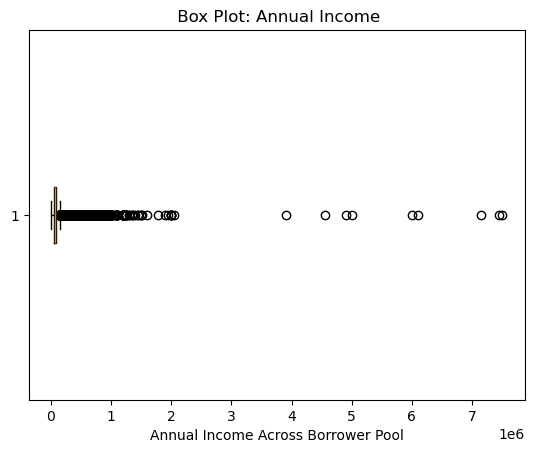

In [327]:
plt.boxplot(data_clean.annual_inc,vert=False);
plt.title(" Box Plot: Annual Income")
plt.xlabel("Annual Income Across Borrower Pool")

- We see the heavy outliers present. This also makes intuitive sense, given that we have large pool of diverse Borrowers.
- High Income is not common but such high values skew the data, as observed from the BOX PLOT above.

In [329]:
q1 = np.percentile(data_clean.annual_inc, 25)
q3 = np.percentile(data_clean.annual_inc, 75)
iqr = q3 - q1
income_cap = q3 + 1.5*iqr
income_floor = q1 - 1.5*iqr
trim_inc = np.where(data_clean.annual_inc < income_floor , income_floor , data_clean.annual_inc )
trim_inc = np.where(data_clean.annual_inc > income_cap , income_cap , data_clean.annual_inc )

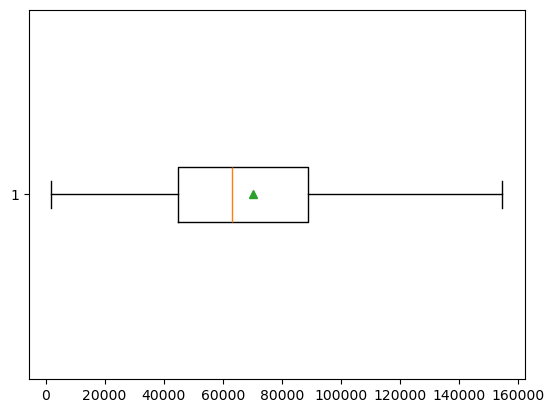

In [330]:
plt.boxplot(trim_inc,vert=False, showmeans=True);

- We have not removed the outliers, simply replaced the outliers with a cap/floor.

In [332]:
data_clean['trim_inc'] = trim_inc

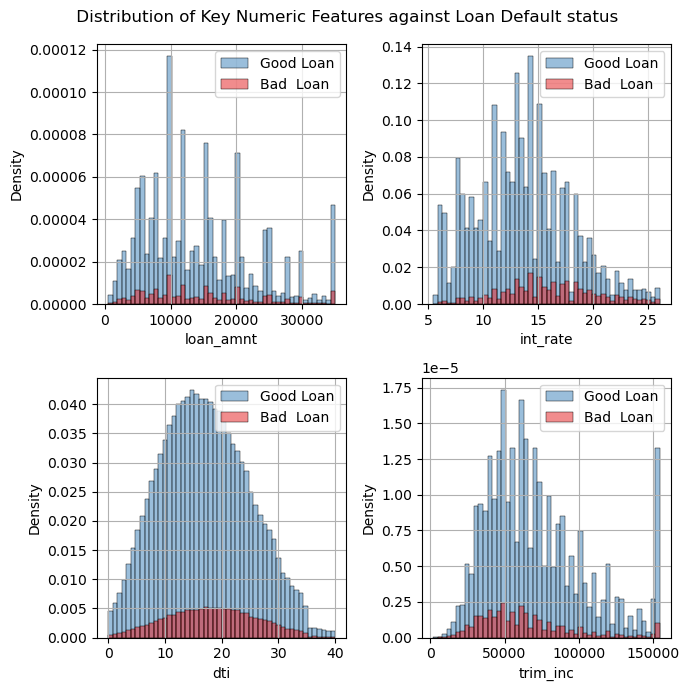

In [333]:
plt.figure(figsize=(7,7))

plt.subplot(2,2,1)
sns.histplot(data=data_clean ,x='loan_amnt',
            hue='good_bad',
             stat='density',
            bins=50,
            palette='Set1')
plt.legend(labels=['Good Loan' , 'Bad  Loan' ])
plt.grid(True)


plt.subplot(2,2,2)
sns.histplot(data=data_clean, x = 'int_rate',
             hue='good_bad',
             stat='density',
            bins=50,
            palette='Set1',
            )
plt.legend(labels=['Good Loan' , 'Bad  Loan' ])
plt.grid(True)

plt.subplot(2,2,3)
sns.histplot(data=data_clean, x = 'dti',
             hue='good_bad',
             stat='density',
             bins= 50,
             palette='Set1')
plt.legend(labels=['Good Loan' , 'Bad  Loan' ])
plt.grid(True)

plt.subplot(2,2,4)
sns.histplot(data=data_clean, x='trim_inc',
            hue='good_bad',
            stat='density',
            bins=50,
            palette= 'Set1')
plt.legend(labels=['Good Loan' , 'Bad  Loan' ])
plt.grid(True)
plt.suptitle(" Distribution of Key Numeric Features against Loan Default status")

plt.tight_layout()

## <U>STATE WISE DEFAULT RATES<U>

In [335]:
def_rate = data_clean.groupby(by ='addr_state')['good_bad'].apply(lambda x:(x==0).mean())

In [336]:
def_rate = (def_rate * 100).sort_values(ascending=False).head(10).reset_index()

In [337]:
def_rate.columns = ['State' , 'Default Rate']

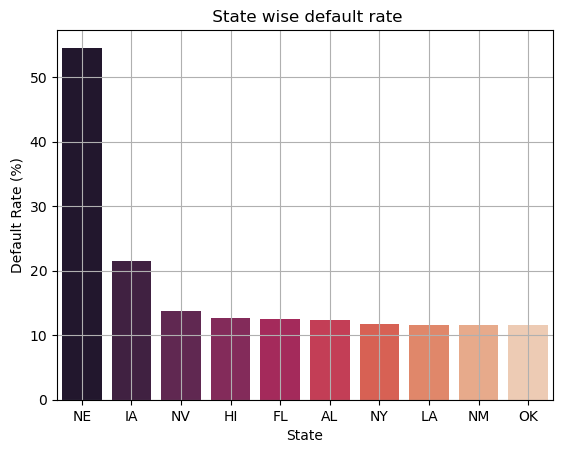

In [338]:
sns.barplot( data= def_rate, y='Default Rate', x='State', hue='State', palette='rocket')
plt.title(" State wise default rate")
plt.ylabel("Default Rate (%)")
plt.grid(True)

## <u>GRADE WISE DEFAULT RATES<u>

In [340]:
def_rate_1 = data_clean.groupby(by ='grade')['good_bad'].apply(lambda x:(x==0).mean())

In [341]:
def_rate_1 = def_rate_1.sort_values(ascending =False).reset_index()

In [342]:
def_rate_1

,grade,good_bad
0,G,0.276853
1,F,0.240891
2,E,0.194616
3,D,0.154012
4,C,0.114789
5,B,0.078577
6,A,0.038711


In [343]:
vol = data_clean.groupby(by ='grade')['loan_amnt'].sum()
vol = vol.reset_index()
vol['loan_amnt'] = vol['loan_amnt']/1000000
vol

,grade,loan_amnt
0,A,1002.679600
1,B,1795.866075
2,C,1777.791500
3,D,1156.900400
4,E,626.479850
5,F,243.563725
6,G,68.182775


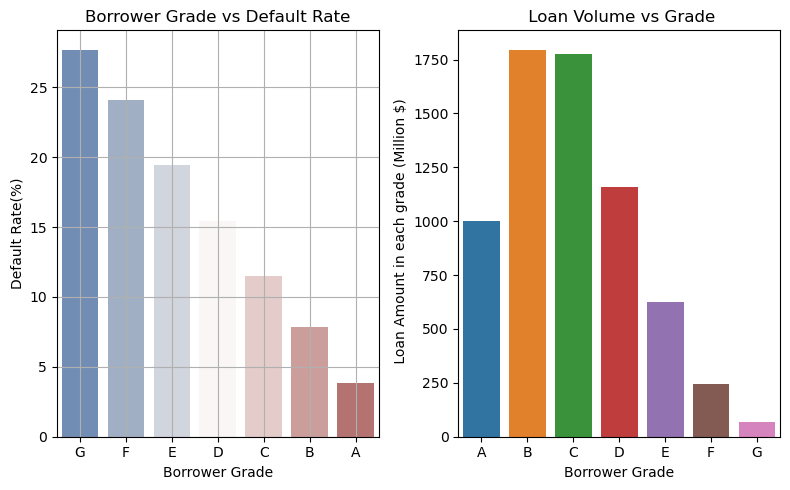

In [344]:
plt.figure(figsize=(8,5))

plt.subplot(1,2,1)
sns.barplot(data = def_rate_1 , x=def_rate_1.grade , y=def_rate_1.good_bad*100, hue='grade', palette='vlag')
plt.xlabel("Borrower Grade")
plt.ylabel("Default Rate(%)")
plt.title("Borrower Grade vs Default Rate")
plt.grid(True)

plt.subplot(1,2,2)
sns.barplot(data = vol , x=vol.grade , y=vol.loan_amnt, hue='grade')
plt.xlabel("Borrower Grade")
plt.ylabel(" Loan Amount in each grade (Million $)")
plt.title(" Loan Volume vs Grade")
plt.tight_layout()

## <U>PURPOSE - DEFAULT RATE<U>

In [346]:
def_rate_2 = data_clean.groupby(by='purpose')['good_bad'].apply(lambda x:(x==0).mean())

In [347]:
def_rate_2 = def_rate_2.sort_values(ascending=False).reset_index()

In [348]:
def_rate_2.head()

,purpose,good_bad
0,small_business,0.215826
1,educational,0.212714
2,renewable_energy,0.153846
3,moving,0.152378
4,house,0.139832


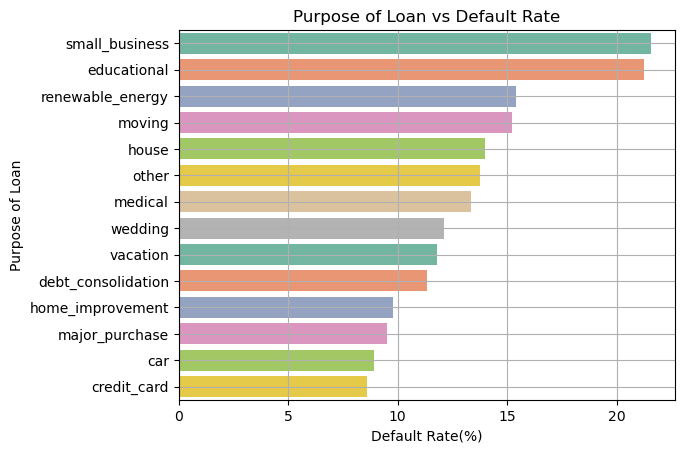

In [349]:
sns.barplot(data=def_rate_2 , x = def_rate_2.good_bad*100 , y= def_rate_2.purpose, hue = 'purpose',
             palette='Set2')
plt.xlabel("Default Rate(%)")
plt.ylabel("Purpose of Loan")
plt.title("Purpose of Loan vs Default Rate")
plt.grid(True)

## <u>LOAN TERM vs DEFAULT RATE<u>

In [351]:
ln_trm = data_clean.groupby(by='term')['good_bad'].apply(lambda x:(x==0).mean())

In [352]:
ln_trm = ln_trm.reset_index()

In [353]:
trm=data_clean.term.value_counts(normalize=True)

In [354]:
ln_trm

,term,good_bad
0,36 months,0.097002
1,60 months,0.141448


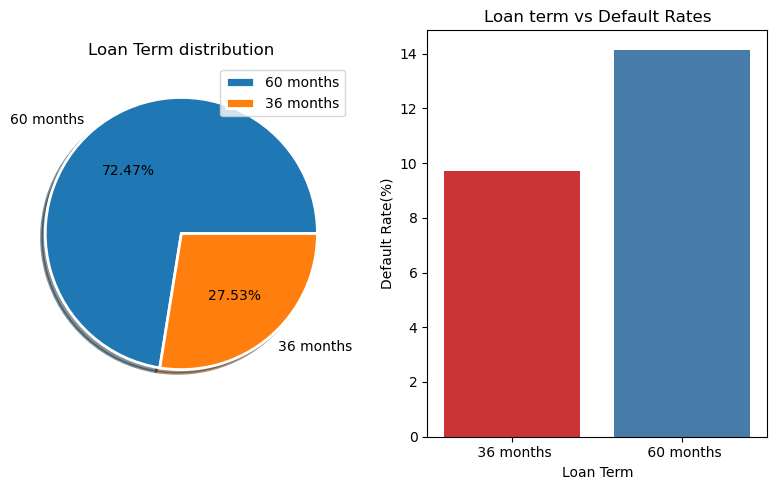

In [355]:
plt.figure(figsize=(8,5))

plt.subplot(1,2,1)
plt.pie(trm,
       autopct='%.2f%%',
       labels=['60 months','36 months'],
       shadow=True,
       wedgeprops = {'edgecolor' : 'white' , 'linewidth' : 2});
plt.legend();
plt.title("Loan Term distribution");

plt.subplot(1,2,2)
sns.barplot( data=ln_trm , x= ln_trm.term , y =ln_trm.good_bad*100, hue='term', palette='Set1')
plt.xlabel("Loan Term")
plt.ylabel("Default Rate(%)")
plt.title("Loan term vs Default Rates")

plt.tight_layout()

## <u>Debt to Income Ratio vs Defaults<u>

In [357]:
dtmi = data_clean.dti.min()
dtma = data_clean.dti.max()
dtmi, dtma

(0.0, 39.99)

In [358]:
bins = [0, 10, 20, 30, 40]
labels = ['0-10', '10-20', '20-30', '30-40']

In [359]:
data_clean['dti_bucket'] = pd.cut(data_clean.dti, bins=bins , labels=labels)

In [360]:
dti_def_rate = data_clean.groupby(by='dti_bucket', observed=True)['good_bad'].apply( lambda x: (x == 0).mean());
dti_def_rate = dti_def_rate.reset_index()

In [361]:
dti_def_rate

,dti_bucket,good_bad
0,0-10,0.088587
1,10-20,0.103416
2,20-30,0.126630
3,30-40,0.132073


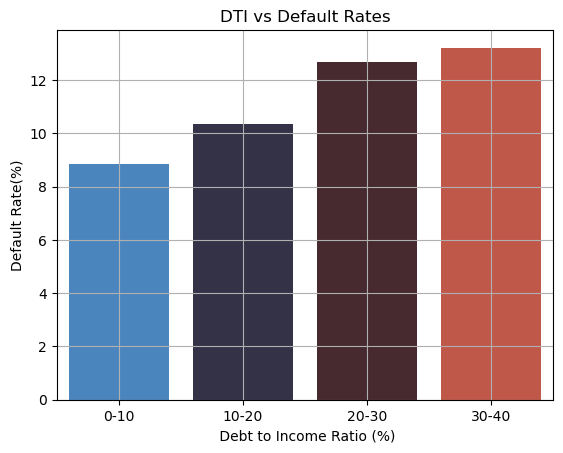

In [362]:
sns.barplot( data=dti_def_rate , x = dti_def_rate.dti_bucket , y = dti_def_rate.good_bad*100 ,
           hue ='dti_bucket',
           palette='icefire')
plt.xlabel(" Debt to Income Ratio (%)")
plt.ylabel("Default Rate(%)")
plt.title("DTI vs Default Rates")
plt.grid(True)

## <u>Interest Rate vs Default<u>

In [364]:
ir_min = data_clean.int_rate.min()
ir_max = data_clean.int_rate.max()

In [365]:
ir_min , ir_max

(5.42, 26.06)

In [366]:
bin = np.arange(5,35,5)
label = ["5-10" , "10-15" , "15-20" , "20-25" , "25-30" ]

In [367]:
ir_bucket = pd.cut(data_clean.int_rate, bins=bin , labels=label)

In [368]:
data_clean['int_bucket'] = ir_bucket
def_ir = data_clean.groupby(by='int_bucket', observed=True)['good_bad'].apply( lambda x: (x==0).mean())

In [369]:
def_ir=def_ir.reset_index()

In [370]:
def_ir

,int_bucket,good_bad
0,5-10,0.041720
1,10-15,0.090778
2,15-20,0.153632
3,20-25,0.215701
4,25-30,0.251627


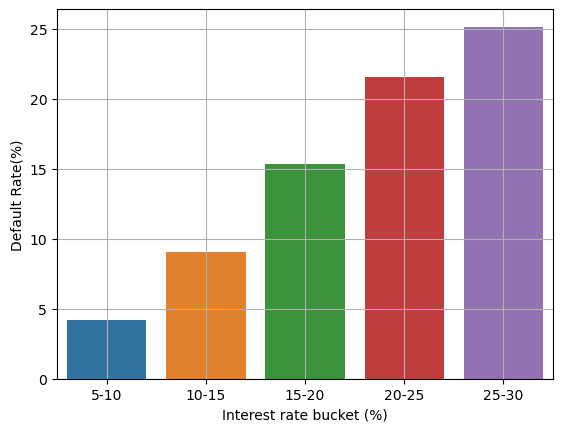

In [371]:
sns.barplot(data=def_ir , x=def_ir.int_bucket , y=def_ir.good_bad*100, hue='int_bucket')
plt.xlabel("Interest rate bucket (%)")
plt.ylabel("Default Rate(%)")
plt.grid(True)

# <u>REGRESSION<u>
## - Data Preparation and Feature Selection

In [373]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [374]:
#data_clean.select_dtypes( include = 'number')
#data_clean.select_dtypes( include = 'object').head()

In [375]:
num_features = ["loan_amnt", "int_rate" , "installment" , "dti" , "annual_inc"]

In [376]:
cat_features = ["grade" , "home_ownership" , "verification_status" ,"purpose" ]

In [377]:
reg_data = data_clean[num_features + cat_features + ["good_bad"]]

### Splitting the data into Train and Test

In [379]:
reg_data = pd.get_dummies(reg_data, columns= cat_features, drop_first=True)

In [380]:
X = reg_data.drop("good_bad", axis=1)
Y = reg_data["good_bad"]

In [381]:
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=100, stratify=Y)

In [382]:
scaler = StandardScaler()

In [383]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# <u>MODEL<u>

In [385]:
model = LogisticRegression( class_weight= "balanced" , max_iter = 1000)
model.fit( X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [485]:
Y_predict = model.predict(X_test)
Y_probability = model.predict_proba(X_test)[:,0]
## selecting the probablity that loan defaults.

In [483]:
Y_probability

array([0.44141433, 0.45334286, 0.39110531, ..., 0.56692588, 0.57030555,
       0.30556341])

In [388]:
Y.value_counts()

good_bad
1    414945
0     50887
Name: count, dtype: int64

# <u>ACCURACY METRICS<U>

In [390]:
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)

In [391]:
print( "Accuracy Score : " , round(accuracy_score(y_test, Y_predict),2))
print( "ROC_AUC Score : " , round(roc_auc_score(y_test, Y_predict),2))

Accuracy Score :  0.61
ROC_AUC Score :  0.63


In [392]:
print("\nConfusion Metric: \n" , confusion_matrix(y_test, Y_predict))


Confusion Metric: 
 [[ 6577  3600]
 [32787 50203]]


In [489]:
print("\nClassification Report: \n", classification_report(y_test, Y_predict))


Classification Report: 
               precision    recall  f1-score   support

           0       0.17      0.65      0.27     10177
           1       0.93      0.60      0.73     82990

    accuracy                           0.61     93167
   macro avg       0.55      0.63      0.50     93167
weighted avg       0.85      0.61      0.68     93167




**<u>Conclusion<u>** — Lending Default Risk

The model achieved an overall accuracy of 61%. However, accuracy
alone does not guarantee performance because the dataset
is imbalanced, with approximately 89% good loans and 11% defaults.

The model achieved a 65% recall for the default class, indicating
that it successfully identified approximately 65% of actual defaulters.
However, its default-class precision was only 17%, meaning that most
loans flagged as potential defaults were actually good loans.
*Consequently, the model generates a substantial number of
false-positive predictions.*

The final model should be selected based on the relative costs of missed defaults and incorrectly flagged
good loans rather than accuracy alone.
